# 05 · Juiz de Fora: onde intervir na linha

**Para quem:** a área de segurança operacional e de relação com as comunidades da MRS, e a prefeitura. No plano de investimentos da renovação da concessão, a MRS prevê cerca de **22 km de vedação** em Juiz de Fora até 2027 e melhorias em **9 travessias de pedestres**, com os pontos a definir ([Tribuna de Minas, 26/03/2023](https://tribunademinas.com.br/noticias/cidade/26-03-2023/mrs-elabora-estudos-tecnicos-para-construcao-de-viadutos-em-juiz-de-fora.html)). A pergunta é onde.

**Como:** os atropelamentos de 2011 a 2025 (RAAF/ANTT) foram postos no traçado da linha pelo km, e a linha foi dividida em trechos de 1 km do km oficial (`fct_acidentes_na_linha_jf`, `fct_trechos_jf`). Cada trecho tem a exposição a até 500 m: moradores (Censo 2022), endereços de comércio e serviço (CNEFE 2022) e escolas (INEP 2023). O ranking é empírico-bayesiano, como no *Highway Safety Manual*. As funções estão em `export/ranking_jf.py`, as mesmas que geram a página, então o número daqui é o do painel.

**O que o dado não permite:**
- **Posição:** o acidente não tem coordenada, só o km. A posição erra de 100 a 300 m, então a rua apontada é a provável, e o trecho tem 1 km, não 500 m.
- **Causa por lugar:** quase metade dos atropelamentos com morte na MRS foi registrada como suicídio. Por isso este notebook não mostra causa por trecho.

In [1]:
import sys; sys.path[:0] = [".", "../ingest", "../export"]
from comum import *
import numpy as np
import ranking_jf as r
from db import conectar
import warnings; warnings.filterwarnings("ignore")
conn = conectar()
trechos, atrop = r.ler(conn)
print(len(trechos), "trechos;", len(atrop), "atropelamentos;", int(atrop.obitos.sum()), "óbitos")

47 trechos; 187 atropelamentos; 101 óbitos


## Pergunta 1. O que explica onde os atropelamentos acontecem: quem mora ou quem circula?

In [2]:
modelos = {
    "só moradores": ["pessoas_500m"],
    "só comércio e serviço": ["comercio_servico_500m"],
    "moradores + comércio": ["comercio_servico_500m", "pessoas_500m"],
}
linhas = []
for nome, exp in modelos.items():
    try:
        _, m = r.ajustar(trechos, exposicao=exp)
        linhas.append({"modelo": nome, "AIC": round(m.aic, 1), "alfa": round(m.params["alpha"], 3),
                       **{f"coef {k}": round(m.params[k], 2) for k in exp}, **{f"p {k}": round(m.pvalues[k], 3) for k in exp}})
    except RuntimeError as erro:
        linhas.append({"modelo": nome, "erro": str(erro)})
import statsmodels.api as sm
poisson = sm.GLM(trechos.atropelamentos, sm.add_constant(np.log1p(trechos[["pessoas_500m"]])),
                 family=sm.families.Poisson(), offset=np.log(trechos.comprimento_m / 1000)).fit()
print(f"Poisson só com moradores: AIC {poisson.aic:.1f}")
pd.DataFrame(linhas).set_index("modelo")

Poisson só com moradores: AIC 197.3


,erro,AIC,alfa,coef comercio_servico_500m,p comercio_servico_500m,coef pessoas_500m,p pessoas_500m
modelo,,,,,,,
só moradores,binomial negativa sem sobredispersão (alfa ~ 0),NaN,NaN,NaN,NaN,NaN,NaN
só comércio e serviço,NaN,163.4,0.227,0.57,0.00,NaN,NaN
moradores + comércio,NaN,164.6,0.220,0.43,0.01,0.16,0.374


**Resposta:** quem circula.
- **Comércio domina:** com as duas exposições no modelo, o coeficiente do comércio e serviço é 0,43 (p = 0,01) e o dos moradores, 0,16 (p = 0,37). O modelo só com comércio tem praticamente o mesmo ajuste (AIC 163 contra 165).
- **Só moradores não serve:** a binomial negativa só com moradores cai sem sobredispersão (α ≈ 0), e a função recusa o ajuste, porque o empírico-bayesiano perderia o sentido. A Poisson equivalente tem AIC de 197.
- **Por quê:** o centro de Juiz de Fora é comercial. Uma conta por morador faria o centro parecer muito mais perigoso do que é.

Fica o modelo com as duas exposições, que era a especificação planejada antes de olhar os dados. A pergunta 3 mostra que o ranking quase não muda com só o comércio.

## Pergunta 2. Quais trechos têm mais atropelamentos do que o movimento explica?

In [3]:
ranking, modelo = r.ajustar(trechos)
t = trechos.merge(ranking.drop(columns="observado"), on="trecho_km")
cols = ["trecho_km", "atropelamentos", "atropelamentos_em_pn", "obitos_atropelamento", "esperado", "eb", "eb_p05", "eb_p95", "excesso", "p_acima_do_esperado"]
t.nsmallest(8, "posicao")[cols].round(2).set_index("trecho_km")

,atropelamentos,atropelamentos_em_pn,obitos_atropelamento,esperado,eb,eb_p05,eb_p95,excesso,p_acima_do_esperado
trecho_km,,,,,,,,,
274,25.0,17.0,16.0,11.26,21.05,15.11,27.80,9.79,1.00
275,32.0,25.0,11.0,21.92,30.27,22.53,38.95,8.35,0.96
273,17.0,4.0,8.0,10.08,14.85,10.01,20.48,4.77,0.95
265,9.0,1.0,5.0,2.19,4.41,2.64,6.54,2.22,0.99
276,19.0,8.0,12.0,17.26,18.64,12.80,25.37,1.38,0.62
284,6.0,2.0,4.0,4.20,5.06,2.80,7.87,0.86,0.69
271,4.0,0.0,1.0,1.81,2.43,1.24,3.94,0.62,0.76
282,6.0,4.0,5.0,5.07,5.56,3.07,8.65,0.49,0.58


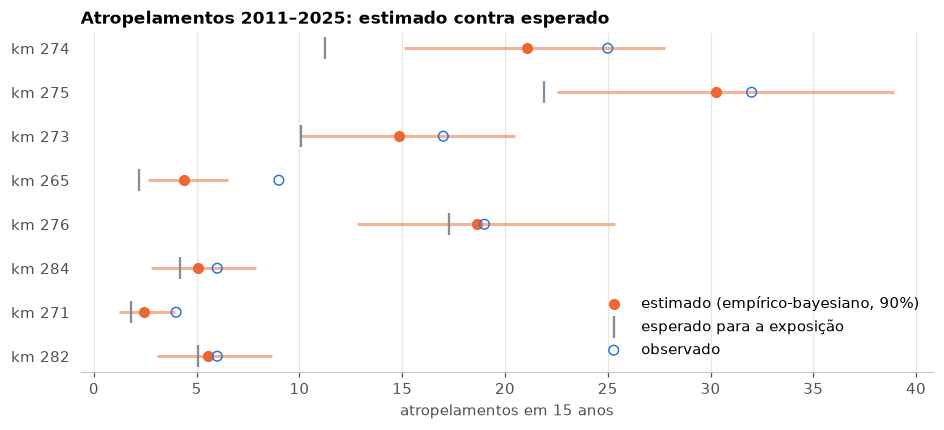

In [4]:
top = t.nsmallest(8, "posicao").iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4))
y = range(len(top))
ax.hlines(y, top.eb_p05, top.eb_p95, color=LARANJA, alpha=0.5, lw=2)
ax.scatter(top.eb, y, color=LARANJA, zorder=3, s=40, label="estimado (empírico-bayesiano, 90%)")
ax.scatter(top.esperado, y, color=CINZA, marker="|", s=200, zorder=3, label="esperado para a exposição")
ax.scatter(top.atropelamentos, y, facecolor="none", edgecolor=AZUL, s=40, zorder=3, label="observado")
ax.set_yticks(list(y), [f"km {k}" for k in top.trecho_km])
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set(title="Atropelamentos 2011–2025: estimado contra esperado", xlabel="atropelamentos em 15 anos")
ax.legend(frameon=False, loc="lower right")
plt.show()

**Resposta:** os km **274, 275 e 273**, nessa ordem, e depois o km 265.
- **km 274:** 25 atropelamentos (17 em passagem em nível) contra 11,3 esperados para o movimento em volta. Excesso estimado de 9,8 em 15 anos, com chance de ~100% de estar acima do esperado.
- **km 275:** o de maior contagem (32), mas também o de maior movimento (2.414 endereços de comércio e serviço). Excesso de 8,4.
- **km 273:** 17 contra 10,1, excesso de 4,8.
- **km 265:** 9 atropelamentos onde se esperavam 2,2, perto do Retiro. Não aparece na contagem bruta. A chance de estar acima do esperado é de 99%.
- **km 276:** é o 3º em contagem bruta (19), mas o movimento explica quase tudo: esperados 17,3, chance de 62%.

## Pergunta 3. O ranking aguenta o erro de posição e a escolha do raio?

In [5]:
robustez = r.robustez_posicao(trechos, atrop)
print("top 3 em 200 sorteios com o km perturbado em ±200 m:", robustez)
so_comercio, _ = r.ajustar(trechos, exposicao=["comercio_servico_500m"])
print("top 5 só com comércio:  ", so_comercio.nsmallest(5, "posicao").trecho_km.tolist())
print("top 5 contagem bruta:   ", trechos.nlargest(5, "atropelamentos").trecho_km.tolist())

top 3 em 200 sorteios com o km perturbado em ±200 m: {274: 200, 273: 200, 275: 186, 276: 10, 265: 4}
top 5 só com comércio:   [274, 273, 275, 265, 284]
top 5 contagem bruta:    [275, 274, 276, 273, 277]


O raio de 500 m está no mart. Para testar 300 e 800 m, esta célula refaz a exposição a partir de `intermediate.int_trechos_jf` e dos setores e endereços do staging. É a única exceção à regra de ler só os marts.

In [6]:
for raio in (300, 500, 800):
    ex = r.consultar(conn, f'''
      with f as (select trecho_km, st_buffer(geom, {raio}, 'endcap=flat') g from intermediate.int_trechos_jf)
      select f.trecho_km,
        coalesce((select sum(s.pessoas * st_area(st_intersection(s.geom, f.g)) / s.area_m2)
                  from staging.stg_ibge__setores_jf s where st_intersects(s.geom, f.g)), 0)::float as pessoas_500m,
        (select count(*) from staging.stg_ibge__enderecos_jf d
         where d.especie = 'comércio e serviço' and st_within(d.geom, f.g))::float as comercio_servico_500m
      from f''')
    rk, m = r.ajustar(trechos.drop(columns=["pessoas_500m", "comercio_servico_500m"]).merge(ex, on="trecho_km"))
    print(f"{raio} m: top 5 {rk.nsmallest(5, 'posicao').trecho_km.tolist()}, excesso dos 3 primeiros {rk.nsmallest(3, 'posicao').excesso.round(1).tolist()}")

300 m: top 5 [275, 274, 273, 265, 276], excesso dos 3 primeiros [11.4, 10.2, 5.7]


500 m: top 5 [274, 275, 273, 265, 276], excesso dos 3 primeiros [9.8, 8.3, 4.8]


800 m: top 5 [275, 274, 273, 265, 276], excesso dos 3 primeiros [10.1, 9.2, 3.9]


**Resposta:** sim, para os três primeiros.
- **Erro de posição:** com ±200 m, os km 274 e 273 ficam no top 3 em todos os 200 sorteios, e o 275 em 186.
- **Raio:** com 300, 500 ou 800 m, os cinco primeiros são os mesmos (273, 274, 275, 265, 276). Só a ordem entre 274 e 275 troca.
- **Exposição só por comércio:** os quatro primeiros também se repetem.

O que não aguenta é o trecho de 500 m. Esse teste foi feito no passo de posicionamento (ver README).

## Pergunta 4. Que intervenção cada trecho pede?

In [7]:
def perfil(k):
    a = atrop[atrop.trecho_km == k]
    horas = a.hora.dropna().map(lambda h: h.hour // 3 * 3).value_counts().sort_index()
    return pd.Series({"atropelamentos": len(a), "% em PN": round(100 * a.em_pn.mean()),
                      "% fim de semana": round(100 * (pd.to_datetime(a.data).dt.weekday >= 5).mean()),
                      "faixa de 3 h com mais casos": f"{horas.idxmax()}h" if len(horas) else None,
                      "horas de circulação interrompida": round(a.interrupcao_h.sum(), 1)})
pd.DataFrame({f"km {k}": perfil(k) for k in t.nsmallest(4, "posicao").trecho_km})

,km 274,km 275,km 273,km 265
atropelamentos,25,32,17,9
% em PN,68,78,24,11
% fim de semana,32,44,12,44
faixa de 3 h com mais casos,0h,9h,9h,3h
horas de circulação interrompida,36.9,41.6,27.1,22.5


**Resposta:** o tipo de lugar muda a intervenção.
- **km 274 (68% em PN) e km 275 (78% em PN):** o atropelamento acontece na passagem em nível. A intervenção é na passagem: travessia de pedestre separada, sinalização e cancela.
  - **km 274:** a rua provável é a Pinto de Moura. Os acidentes em PN se repetem no km 274,59 (8 vezes), a ~80 m dela, e no km 274,19 (6), perto de caminhos de pedestre.
  - **km 275:** a rua provável é a Halfeld, na Praça da Estação.
- **km 273 (76% fora de PN):** as pessoas atravessam onde não há travessia, perto da Rua João Luiz de Barros. A intervenção é vedação com uma travessia segura no caminho que as pessoas já fazem; sem a travessia, a grade é aberta de novo.
- **km 265 (89% fora de PN):** o mesmo caso do 273.
- **Coincidência com o plano da MRS:** a Rua João Luiz de Barros e a Praça da Estação são duas das três passagens em nível que o plano manda melhorar.

## Pergunta 5. Quanto vale reduzir o excesso?

In [8]:
custo, letalidade = r.custo_do_excesso(ranking, atrop)
print(f"letalidade dos atropelamentos em JF: {letalidade:.0%}; custo social por óbito: R$ {r.CUSTO_OBITO_RS/1e6:.2f} milhão")
custo.merge(ranking[["trecho_km", "posicao"]]).nsmallest(5, "posicao").round(3).set_index("trecho_km")

letalidade dos atropelamentos em JF: 54%; custo social por óbito: R$ 1.18 milhão


,excesso,excesso_por_ano,obitos_evitaveis_por_ano,valor_social_por_ano_rs,posicao
trecho_km,,,,,
274,9.791,0.653,0.353,415737.024,1
275,8.348,0.557,0.301,354489.393,2
273,4.768,0.318,0.172,202468.227,3
265,2.215,0.148,0.080,94056.263,4
276,1.376,0.092,0.050,58436.952,5


**Resposta:** cerca de **R$ 970 mil por ano** nos três primeiros trechos.
- **Volume:** o excesso dos três soma ~1,5 atropelamento por ano. Com a letalidade de 54%, são ~0,8 óbito por ano.
- **Custo por óbito:** R$ 1,18 milhão, o custo social de um acidente rodoviário com morte (Ipea/PRF, 2014: R$ 646,7 mil) corrigido pelo IPCA até dez/2025. É ordem de grandeza: a conta foi feita para acidente de trânsito, não para atropelamento por trem.
- **Piso, não teto:** é o ganho de levar cada trecho à média de trechos parecidos. Uma vedação bem feita pode ganhar mais.
- **Prejuízo declarado:** não entra. Ele é R$ 0 em todos os 70 atropelamentos que têm o campo preenchido.

## Pergunta 6. A passarela restaurada na Estação Central mudou alguma coisa?

In [9]:
import export_jf
export_jf.antes_e_depois(atrop)

{'trecho_km': 275,
 'antes': [20, 99],
 'depois': [8, 44],
 'razao': 0.9,
 'ic95': [0.34, 2.13],
 'p': 1.0}

**Resposta:** não dá para saber.
- **A obra:** a passarela de 1928 da Estação Central (km 275) foi restaurada de ago/2021 a fev/2022 ([Via Trólebus](https://viatrolebus.com.br/2022/03/mrs-restaura-passarela-historica-em-juiz-de-fora/)).
- **O resultado:** contra o resto de JF, a variação dos atropelamentos no trecho entre 2011–2020 e 2022–2025 foi de 0,90 vez, com intervalo de 95% de 0,34 a 2,13.
- **O limite:** com 8 casos depois, só uma queda de mais de ~2/3 seria detectável.
- **O que fazer:** registrar a data de cada obra do plano da MRS, para avaliar as próximas.

## Conclusão
1. **km 274 e km 275:** tratar as passagens em nível, nas ruas prováveis Pinto de Moura e Halfeld (Praça da Estação).
2. **km 273 e km 265:** vedar e abrir travessia segura onde as pessoas já atravessam.
3. **Avaliação das obras:** as obras do plano da MRS devem ter data e local registrados.

O excesso dos três primeiros trechos vale cerca de R$ 1 milhão por ano em custo social. O ranking não muda com o raio da exposição nem com 200 m de erro de posição.

> Se você está passando por um momento difícil, o [CVV](https://cvv.org.br/) atende de graça, 24 horas, pelo telefone **188**.